# Module 2: Credit Risk (Corporate & Retail Lending)

**Business question:** NovaFin wants to lend more while defaulting less. Which loans should we **approve, review or reject**?

**Chain:** loan data → ML probability of default (PD) → expected credit loss (ECL = PD × LGD × EAD) → risk band → credit decision.

**What you will learn:** PD modelling, ROC-AUC and the KS statistic, probability calibration, ECL, turning a model into a credit policy, and SHAP reason codes for rejected borrowers.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_loans.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect
Monetary columns here are in plain rupees (a typical loan is about ₹10 lakh). Per the course, `Customer_ID` is unique per row and serves as the **loan ID**.

In [2]:
df = pd.read_csv(DATA / "nova_loans.csv")
print(df.shape, "| missing:", df.isna().sum().sum(), "| Customer_ID unique:", df["Customer_ID"].is_unique)
print("Default rate:", df["Default_Flag"].mean().round(3))
df.head()

(5000, 14) | missing: 0 | Customer_ID unique: True
Default rate: 0.199


,Customer_ID,Customer_Type,Annual_Income,Employment_Length,Debt_to_Income,Credit_Score,Existing_Loan,Loan_Amount,Loan_Term_Months,Interest_Rate,Collateral_Value,Past_Default,Sector_Risk,Default_Flag
0,200001,Corporate,939967.04,29,0.248,698,1009401.25,1968503.82,12,8.96,2690085.58,0,65.31,0
1,200002,Retail,1629687.82,2,0.150,747,986482.96,1932554.81,12,7.82,2542892.81,0,33.98,0
2,200003,Corporate,1971716.74,18,0.300,718,1822182.57,815975.44,60,7.13,1202025.19,0,55.13,0
3,200004,Corporate,1848108.58,8,0.082,657,1169299.09,3855380.75,36,12.97,5571538.48,1,75.27,0
4,200005,Retail,673064.61,27,0.111,544,383728.34,749360.88,36,9.18,1272953.05,0,55.35,0


## 2. Exploratory analysis

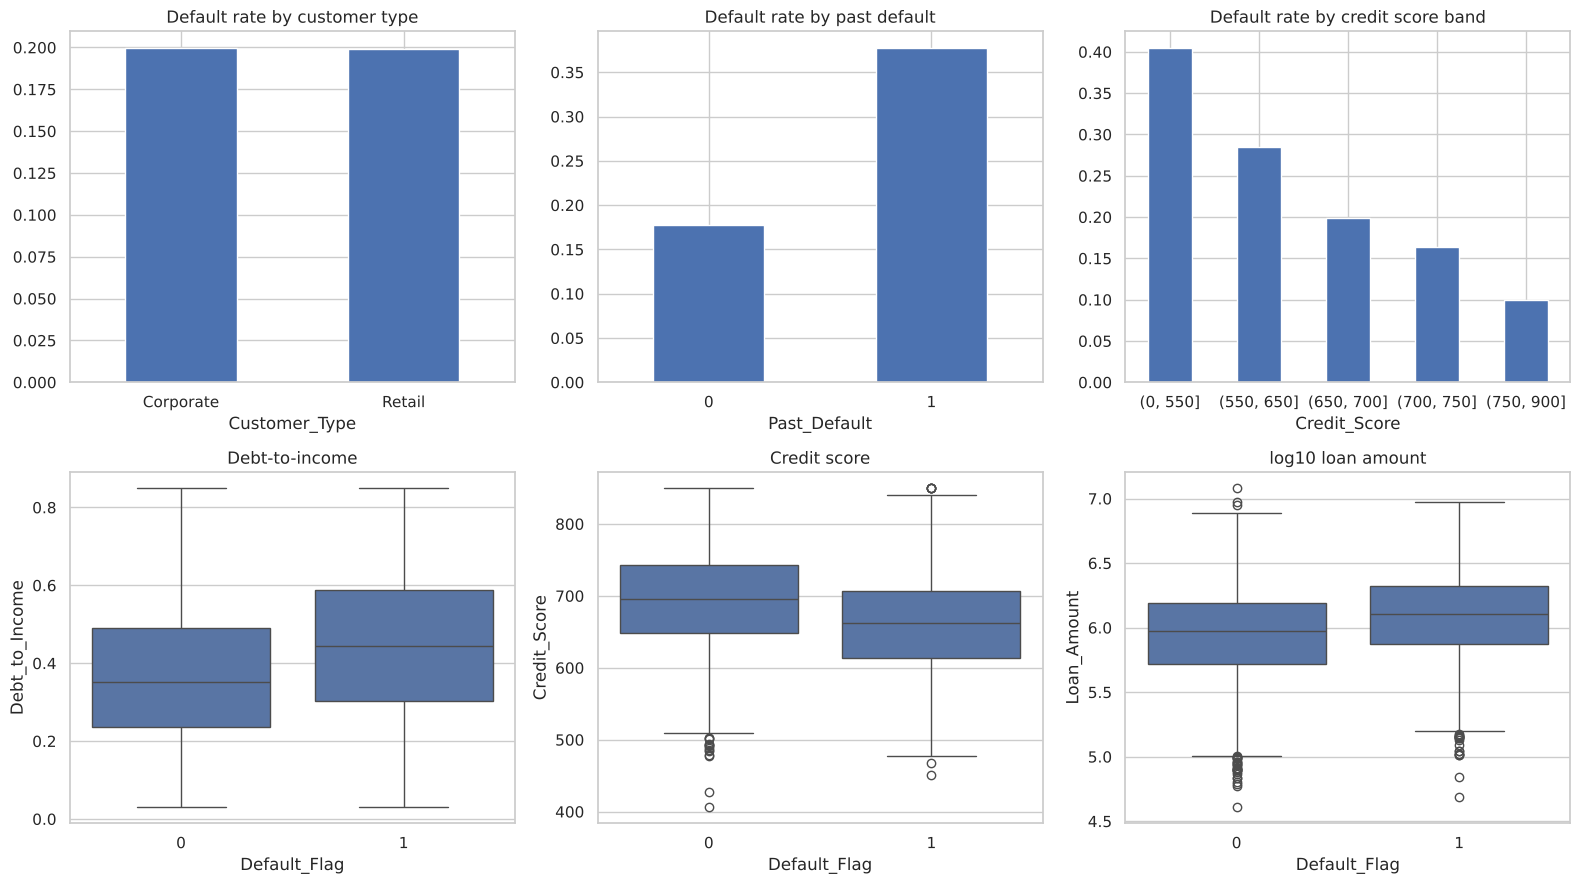

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
df.groupby("Customer_Type")["Default_Flag"].mean().plot.bar(ax=ax[0, 0], rot=0, title="Default rate by customer type")
df.groupby("Past_Default")["Default_Flag"].mean().plot.bar(ax=ax[0, 1], rot=0, title="Default rate by past default")
bands = pd.cut(df["Credit_Score"], [0, 550, 650, 700, 750, 900])
df.groupby(bands)["Default_Flag"].mean().plot.bar(ax=ax[0, 2], rot=0, title="Default rate by credit score band")
sns.boxplot(data=df, x="Default_Flag", y="Debt_to_Income", ax=ax[1, 0]).set_title("Debt-to-income")
sns.boxplot(data=df, x="Default_Flag", y="Credit_Score", ax=ax[1, 1]).set_title("Credit score")
sns.boxplot(data=df, x="Default_Flag", y=np.log10(df["Loan_Amount"]), ax=ax[1, 2]).set_title("log10 loan amount")
plt.tight_layout(); plt.show()

**What the EDA says:** default is ~20% for both retail and corporate. Past defaulters default twice as often (38% vs 18%). Lower credit score and higher debt-to-income clearly raise risk.

## 3. Feature engineering
Finance ratios a credit officer would use:
- **LTV** (loan-to-value) = Loan_Amount ÷ Collateral_Value: how well the collateral covers the loan.
- **Loan-to-income** = Loan_Amount ÷ Annual_Income.
- **Total debt-to-income** = (Existing_Loan + Loan_Amount) ÷ Annual_Income.

**Leakage note:** `Interest_Rate` is the price NovaFin already set, which reflects an old risk view. We keep it (it is known at decision time), but a pricing model should drop it.

In [4]:
X = df.drop(columns=["Customer_ID", "Default_Flag"]).copy()
y = df["Default_Flag"]
X["LTV"] = X["Loan_Amount"] / X["Collateral_Value"]
X["Loan_to_Income"] = X["Loan_Amount"] / X["Annual_Income"]
X["Total_Debt_to_Income"] = (X["Existing_Loan"] + X["Loan_Amount"]) / X["Annual_Income"]
X = pd.get_dummies(X, columns=["Customer_Type"], drop_first=True, dtype=float)
X.columns.tolist()

['Annual_Income',
 'Employment_Length',
 'Debt_to_Income',
 'Credit_Score',
 'Existing_Loan',
 'Loan_Amount',
 'Loan_Term_Months',
 'Interest_Rate',
 'Collateral_Value',
 'Past_Default',
 'Sector_Risk',
 'LTV',
 'Loan_to_Income',
 'Total_Debt_to_Income',
 'Customer_Type_Retail']

## 4. Train / test split and models
70/30 split, **stratified** so both sets keep the 20% default rate. Models are trained on train only and judged on test.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, average_precision_score
from scipy.stats import ks_2samp

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=20, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbosity=0),
}
rows, probs = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; probs[name] = p
    ks = ks_2samp(p[y_te == 1], p[y_te == 0]).statistic
    rows.append([name, roc_auc_score(y_te, p), ks, average_precision_score(y_te, p), brier_score_loss(y_te, p)])
results = pd.DataFrame(rows, columns=["Model", "ROC-AUC", "KS", "PR-AUC", "Brier"]).set_index("Model").round(3)
results

,ROC-AUC,KS,PR-AUC,Brier
Model,,,,
Logistic regression,0.740,0.382,0.418,0.140
Random forest,0.731,0.364,0.422,0.141
XGBoost,0.720,0.343,0.411,0.142


**Metrics explained:**
- **ROC-AUC:** chance the model ranks a random defaulter above a random non-defaulter.
- **KS:** the biggest gap between the score distributions of defaulters and non-defaulters; banks often want KS > 0.3.
- **Brier score:** mean squared error of the probabilities (lower = better calibrated). Important because ECL uses the PD *value*, not only the ranking.

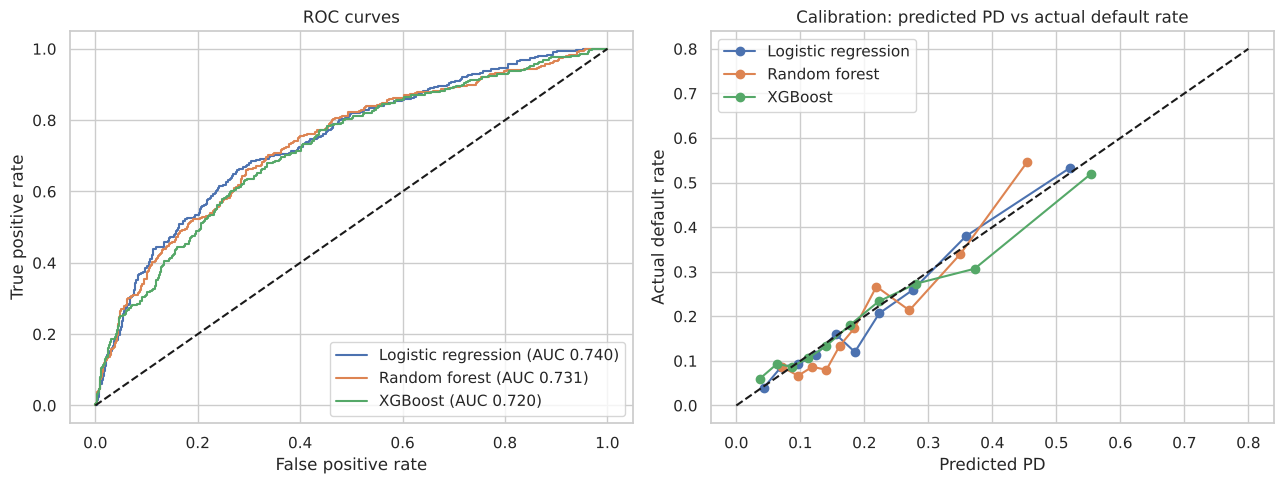

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()
from sklearn.calibration import calibration_curve
for name, p in probs.items():
    fr, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile"); ax[1].plot(mp, fr, "o-", label=name)
ax[1].plot([0, 0.8], [0, 0.8], "k--"); ax[1].set(title="Calibration: predicted PD vs actual default rate", xlabel="Predicted PD", ylabel="Actual default rate"); ax[1].legend()
plt.tight_layout(); plt.show()

**Model choice:** logistic regression is as good as (or better than) the tree models here, is well calibrated, and is the industry standard for PD because every coefficient can be explained to a regulator. We use it as the production PD model.

## 5. Explainability
Coefficients show the direction of each driver. A SHAP waterfall gives the **reason codes** for one rejected borrower, which a bank must be able to explain.

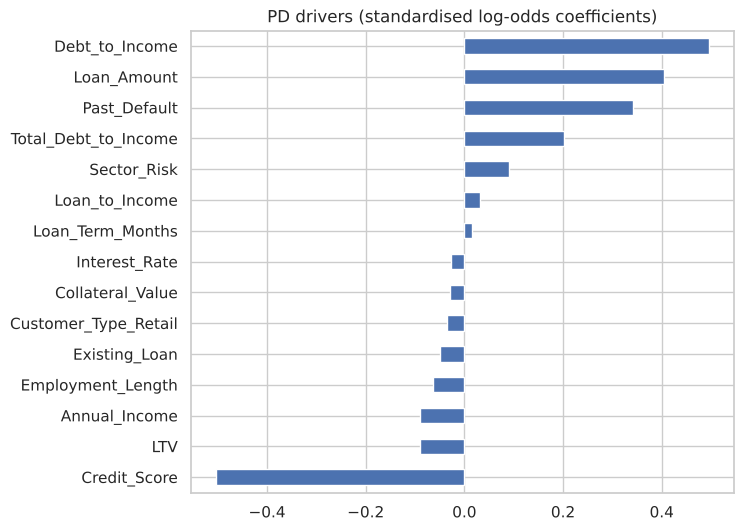

In [7]:
best = models["Logistic regression"]
coef = pd.Series(best[-1].coef_[0], index=X.columns).sort_values()
coef.plot.barh(figsize=(7, 6), title="PD drivers (standardised log-odds coefficients)"); plt.show()

Background dataset has 3500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3500 when initializing the masker.


Highest-risk test borrower, predicted PD = 0.859


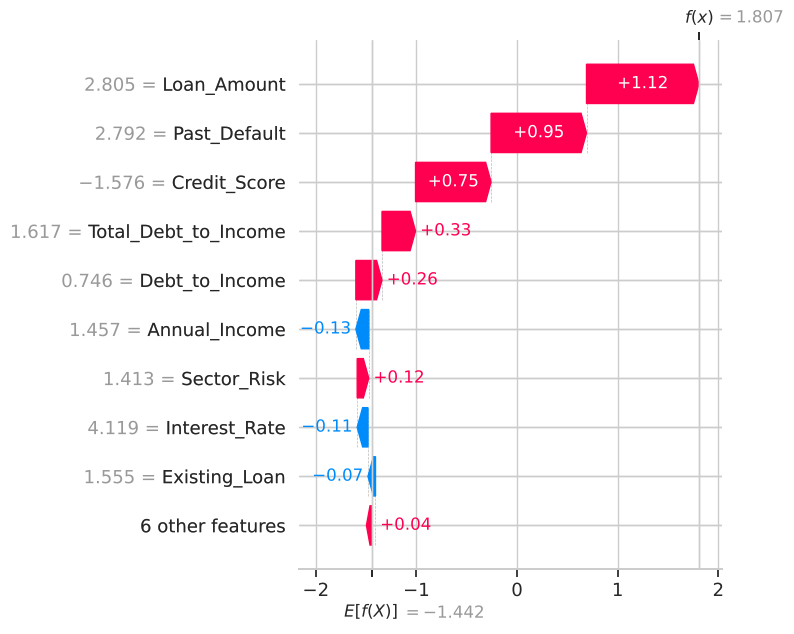

In [8]:
import shap
explainer = shap.LinearExplainer(best[-1], best[0].transform(X_tr), feature_names=X.columns.tolist())
sv = explainer(best[0].transform(X_te))
i = int(np.argmax(probs["Logistic regression"]))
print("Highest-risk test borrower, predicted PD =", round(probs["Logistic regression"][i], 3))
shap.plots.waterfall(sv[i], max_display=10, show=False); plt.tight_layout(); plt.show()

## 6. PD for every loan
Each loan gets an **out-of-fold** PD: it is scored by a model trained on the other 80% of loans, so no loan is scored by a model that saw its own outcome.

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
df["Predicted_PD"] = cross_val_predict(best, X, y, cv=skf, method="predict_proba")[:, 1]
print("Out-of-fold AUC:", round(roc_auc_score(y, df["Predicted_PD"]), 3))

Out-of-fold AUC: 0.733


## 7. Risk categories: are the suggested bands sensible?
The brief suggests <5% Low, 5–15% Medium, 15–30% High, >30% Very High, and asks us to justify rather than blindly adopt. We check how many loans fall in each band and whether actual default rates rise band by band.

In [10]:
BANDS = [0, 0.05, 0.15, 0.30, 1.0]
LABELS = ["Low", "Medium", "High", "Very High"]
df["Risk_Category"] = pd.cut(df["Predicted_PD"], BANDS, labels=LABELS)
band_check = df.groupby("Risk_Category", observed=False).agg(loans=("Customer_ID", "count"), avg_PD=("Predicted_PD", "mean"),
                                                             actual_default=("Default_Flag", "mean"), exposure_cr=("Loan_Amount", lambda s: s.sum() / 1e7)).round(3)
band_check["share"] = (band_check["loans"] / len(df)).round(3)
band_check

,loans,avg_PD,actual_default,exposure_cr,share
Risk_Category,,,,,
Low,339,0.037,0.032,23.410,0.068
Medium,1963,0.098,0.097,188.507,0.393
High,1690,0.212,0.209,237.283,0.338
Very High,1008,0.432,0.438,190.454,0.202


**Justification:** actual default rates rise steadily across the bands and sit close to the average predicted PD in each band, so the model is well calibrated and the bands separate risk. The Low band is small (few borrowers have PD < 5%), which is expected in a book with a 20% base default rate. We keep the brief's bands.

## 8. Expected Credit Loss
$$ECL_i = PD_i \times LGD \times EAD_i, \qquad LGD = 40\%, \quad EAD = \text{Loan Amount}$$
As a sensitivity, we also compute a collateral-adjusted LGD = max(0, 1 − 0.7 × Collateral ÷ Loan), assuming a 30% haircut when collateral is sold.

In [11]:
LGD = 0.40
df["ECL"] = df["Predicted_PD"] * LGD * df["Loan_Amount"]
df["LGD_collateral"] = (1 - 0.7 * df["Collateral_Value"] / df["Loan_Amount"]).clip(lower=0)
df["ECL_collateral"] = df["Predicted_PD"] * df["LGD_collateral"] * df["Loan_Amount"]
print(f"Total exposure: ₹{df.Loan_Amount.sum()/1e7:,.1f} crore")
print(f"Total ECL (LGD 40%): ₹{df.ECL.sum()/1e7:,.1f} crore  = {df.ECL.sum()/df.Loan_Amount.sum():.2%} of exposure")
print(f"Total ECL (collateral LGD): ₹{df.ECL_collateral.sum()/1e7:,.1f} crore")

Total exposure: ₹639.7 crore
Total ECL (LGD 40%): ₹62.9 crore  = 9.83% of exposure
Total ECL (collateral LGD): ₹30.9 crore


## 9. Credit decision: Approve / Review / Reject
First we ask: at what PD does a loan stop making money? **Assumptions (state them in the report):**
- PD and ECL cover the life of the loan, so income must too. Loans amortise, so the average balance is about 55% of the loan over the term.
- Cost of funds = 6.0% a year.
- Expected profit = Loan × (Interest_Rate − 6%) × 0.55 × term in years × (1 − PD) − ECL.

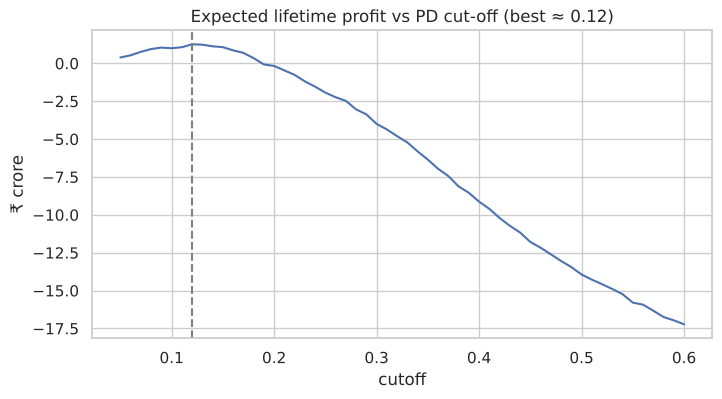

In [12]:
COF = 0.06
df["Bal_Years"] = 0.55 * df["Loan_Term_Months"] / 12            # average-balance years of exposure
df["Exp_Profit"] = df["Loan_Amount"] * (df["Interest_Rate"] / 100 - COF) * df["Bal_Years"] * (1 - df["Predicted_PD"]) - df["ECL"]
df["Breakeven_Rate"] = COF + df["ECL"] / (df["Loan_Amount"] * df["Bal_Years"] * (1 - df["Predicted_PD"]))
cuts = np.arange(0.05, 0.61, 0.01)
curve = pd.DataFrame({"cutoff": cuts,
                      "approval_rate": [(df.Predicted_PD < c).mean() for c in cuts],
                      "profit_cr": [df.loc[df.Predicted_PD < c, "Exp_Profit"].sum() / 1e7 for c in cuts]})
best_cut = curve.loc[curve.profit_cr.idxmax(), "cutoff"]
ax = curve.plot(x="cutoff", y="profit_cr", figsize=(8, 4), title=f"Expected lifetime profit vs PD cut-off (best ≈ {best_cut:.2f})", legend=False)
ax.set_ylabel("₹ crore"); ax.axvline(best_cut, ls="--", c="grey"); plt.show()

**Is NovaFin pricing risk correctly?** Compare the rate charged with the break-even rate (cost of funds + annual expected loss) in each band.

In [13]:
df.groupby("Risk_Category", observed=False).agg(rate_charged=("Interest_Rate", "mean"), breakeven_rate=("Breakeven_Rate", lambda s: 100 * s.mean())).round(2)

,rate_charged,breakeven_rate
Risk_Category,,
Low,7.54,7.14
Medium,8.18,9.02
High,9.67,13.25
Very High,12.57,29.12


**Finding:** the rate charged rises with risk, but not fast enough. High and Very High PD loans are priced below their break-even rate, so they lose money on average even before operating costs. Two levers follow: **reject** the riskiest loans, and **reprice** High-PD loans to at least break-even if NovaFin wants to grow there.

**Policy (combines PD, ECL, loan size, collateral and risk appetite):**
- **Approve:** PD < 15% (Low/Medium), unless the loan is in the largest 5% of loans, which goes to **Review**.
- **Review:** PD 15–30% (High). Approve on manual review only if collateral covers the loan (LTV ≤ 80%).
- **Reject:** PD > 30% (Very High). The expected-profit curve shows these loans destroy value on average.

In [14]:
big = df["Loan_Amount"].quantile(0.95)
def decide(r):
    if r["Predicted_PD"] > 0.30: return "Reject"
    if r["Predicted_PD"] >= 0.15: return "Review"
    return "Review" if r["Loan_Amount"] > big else "Approve"
df["Decision"] = df.apply(decide, axis=1)
policy = df.groupby("Decision").agg(loans=("Customer_ID", "count"), exposure_cr=("Loan_Amount", lambda s: s.sum() / 1e7),
                                    ECL_cr=("ECL", lambda s: s.sum() / 1e7), actual_default=("Default_Flag", "mean"),
                                    exp_profit_cr=("Exp_Profit", lambda s: s.sum() / 1e7)).round(2)
policy

,loans,exposure_cr,ECL_cr,actual_default,exp_profit_cr
Decision,,,,,
Approve,2278,201.81,7.60,0.09,0.86
Reject,1008,190.45,34.29,0.44,-18.72
Review,1714,247.39,21.01,0.21,-4.86


In [15]:
approve_all = df.ECL.sum() / df.Loan_Amount.sum()
ok = df.Decision == "Approve"
print(f"Approve everyone: default rate {df.Default_Flag.mean():.1%}, ECL rate {approve_all:.2%}")
print(f"Our policy (Approve only): approval {ok.mean():.1%}, default rate {df[ok].Default_Flag.mean():.1%}, ECL rate {df[ok].ECL.sum()/df[ok].Loan_Amount.sum():.2%}")
print(f"Expected lifetime profit: approve everyone ₹{df.Exp_Profit.sum()/1e7:,.1f} cr vs our Approve book ₹{df[ok].Exp_Profit.sum()/1e7:,.1f} cr")

Approve everyone: default rate 19.9%, ECL rate 9.83%
Our policy (Approve only): approval 45.6%, default rate 8.9%, ECL rate 3.77%
Expected lifetime profit: approve everyone ₹-22.7 cr vs our Approve book ₹0.9 cr


## 10. Segment view for Module 9
For capital allocation we need the **annual risk-adjusted return** of retail and corporate lending under our policy: expected profit ÷ (average balance × years).

In [16]:
appr = df[df.Decision == "Approve"]
seg = appr.groupby("Customer_Type").apply(lambda g: pd.Series({
    "loans": len(g), "exposure_cr": g.Loan_Amount.sum() / 1e7,
    "avg_rate": (g.Interest_Rate * g.Loan_Amount).sum() / g.Loan_Amount.sum() / 100,
    "annual_loss_rate": g.ECL.sum() / (g.Loan_Amount * g.Bal_Years).sum(),
    "annual_risk_adj_return": g.Exp_Profit.sum() / (g.Loan_Amount * g.Bal_Years).sum(),
    "avg_PD": g.Predicted_PD.mean(),
})).round(4)
seg

,loans,exposure_cr,avg_rate,annual_loss_rate,annual_risk_adj_return,avg_PD
Customer_Type,,,,,,
Corporate,603.0,53.3325,0.0822,0.0182,0.0018,0.0903
Retail,1675.0,148.4794,0.0813,0.0171,0.0020,0.0884


## 11. Save outputs

In [17]:
df[["Customer_ID", "Customer_Type", "Loan_Amount", "Predicted_PD", "Risk_Category", "ECL", "Exp_Profit", "Decision"]].rename(columns={"Customer_ID": "Loan_ID"}).round(4).to_csv(OUT / "m2_loan_decisions.csv", index=False)
seg.to_csv(OUT / "m2_segments.csv")
print("Saved", OUT / "m2_loan_decisions.csv")

Saved ../outputs/m2_loan_decisions.csv


## 12. Conclusions
1. Logistic regression gives a well-calibrated PD with ROC-AUC ≈ 0.74; tree models add nothing, so the simpler, explainable model wins.
2. Main default drivers: low credit score, high debt-to-income, large loans, past default and high loan-to-income.
3. The suggested PD bands are kept: actual default rises cleanly from band to band.
4. The policy approves Low/Medium-PD loans, reviews High-PD and very large loans, and rejects Very High PD. This cuts the default rate of the approved book from ~20% to ~9% and the ECL rate from ~9.8% to ~3.8% of exposure.
5. Current pricing does not cover risk for High and Very High PD loans. Lending growth should come from Low/Medium-PD borrowers, with risk-based repricing before growing in higher bands.
6. **Limits:** assumed 40% LGD (conservative: collateral-adjusted ECL is about half), 6% cost of funds, no operating costs, synthetic data. Monitor PD drift and recalibrate yearly.